In [1]:
!pip install minisom

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for minisom: filename=minisom-2.3.6-py3-none-any.whl size=13171 sha256=467c14457b4d8138400eb05a4e4479b81cd93929a785bf0ea971211bd0d3e200
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built minisom


Dataset:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0  

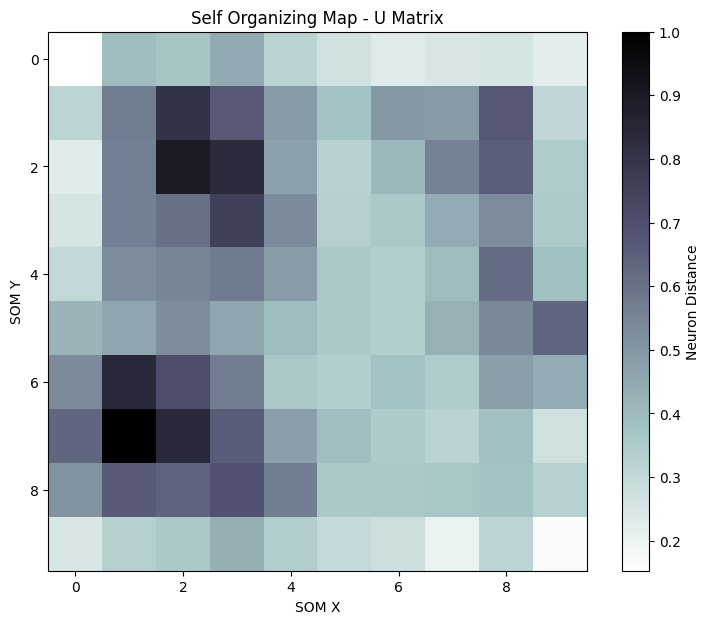

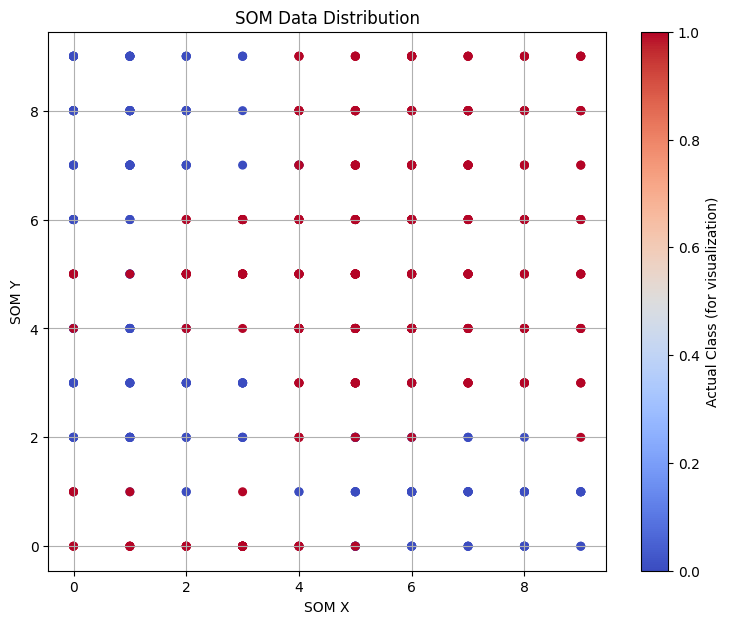


SOM Cluster Assignments:
   SOM_X  SOM_Y
0      1      7
1      0      9
2      0      6
3      2      2
4      0      6
5      1      2
6      6      1
7      0      2
8      1      2
9      2      2

Number of Data Points in Each Neuron:
SOM_X  SOM_Y
3      0        16
6      4        15
5      5        14
       4        13
3      6        11
0      6        11
4      4        11
1      8        10
2      5        10
3      5        10
dtype: int64

Quantization Error: 0.30551510422289363


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom

# 1. Load Dataset
data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)

print("Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

# 2. Select Features
X = df.values

# 3. Normalize Data
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# 4. Initialize SOM
som = MiniSom(
    x=10,
    y=10,
    input_len=X_scaled.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

# 5. Initialize Weights
som.random_weights_init(X_scaled)

# 6. Train SOM
som.train_random(X_scaled, 1000)

print("\nSOM Training Completed")

# 7. Calculate Best Matching Units
winners = np.array([som.winner(x) for x in X_scaled])

# 8. Visualize U-Matrix
plt.figure(figsize=(9, 7))

plt.imshow(som.distance_map().T, cmap='bone_r')
plt.colorbar(label='Neuron Distance')

plt.title("Self Organizing Map - U Matrix")
plt.xlabel("SOM X")
plt.ylabel("SOM Y")

plt.show()

# 9. Visualize Data Distribution
plt.figure(figsize=(9, 7))

plt.scatter(
    winners[:, 0],
    winners[:, 1],
    c=data.target,
    cmap='coolwarm',
    s=30
)

plt.title("SOM Data Distribution")
plt.xlabel("SOM X")
plt.ylabel("SOM Y")

plt.colorbar(label='Actual Class (for visualization)')
plt.grid()
plt.show()

# 10. Display Cluster Information
df['SOM_X'] = winners[:, 0]
df['SOM_Y'] = winners[:, 1]

print("\nSOM Cluster Assignments:")
print(df[['SOM_X', 'SOM_Y']].head(10))

print("\nNumber of Data Points in Each Neuron:")
print(
    df.groupby(['SOM_X', 'SOM_Y'])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

# 11. Quantization Error
error = som.quantization_error(X_scaled)

print("\nQuantization Error:", error)
